# 09 · Vision: evaluating the warehouse object detector

**Phase 5 · Computer vision.** `cloud/train_yolo_colab.ipynb` fine-tuned **YOLO11s** (a COCO-pretrained
object detector) on 2,400 camera images rendered from our 3D warehouse, on a free Colab T4 GPU, and
saved it in `models/vision_yolo_v1/`. This notebook evaluates that model **on this laptop (CPU)**:

1. the training run (from Colab's logs);
2. the official test scores, reproduced locally, and the speed / accuracy trade-off on a CPU;
3. **where it fails**: per class, per object size, per camera type;
4. **per-class confidence thresholds** chosen on validation, safety classes first;
5. examples: what the model sees and what it misses.

**Classes:** robot, worker, shelf, package (dropped parcel), obstacle (fallen pallet etc.),
blocked_path (closure barrier). Split by simulation run: train 1,680 images, validation 384,
test 336. The test images were never used for training or for any choice in this notebook.

In [1]:
import json
import sys
import time
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from PIL import Image, ImageDraw

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "processed").exists())
sys.path.insert(0, str(ROOT))
from ultralytics import YOLO  # noqa: E402

from ai.computer_vision.evaluation import SIZES, choose_threshold, match_split, prf, read_labels  # noqa: E402

RUN = ROOT / "models" / "vision_yolo_v1"
EXPORT = ROOT / "data" / "exports"
DATA = EXPORT / "warehouse_vision"  # the exact JPEG images the model was trained on
if not DATA.exists():  # made by scripts/package_vision_dataset.py
    with zipfile.ZipFile(EXPORT / "warehouse_vision_v3.zip") as z:
        z.extractall(EXPORT)
cfg = yaml.safe_load((DATA / "data.yaml").read_text())
cfg["path"] = str(DATA)
DATA_YAML = EXPORT / "warehouse_vision_local.yaml"
DATA_YAML.write_text(yaml.safe_dump(cfg))
NAMES = cfg["names"]
W, H = 640, 480
frames = pd.read_csv(DATA / "frames.csv").set_index("frame")
model = YOLO(str(RUN / "best.pt"))
colab = json.loads((RUN / "report.json").read_text())
print("model:", colab["algorithm"], "| classes:", NAMES)

model: YOLO11s (Ultralytics), COCO-pretrained, fine-tuned | classes: ['robot', 'worker', 'shelf', 'package', 'obstacle', 'blocked_path']


## 1. The training run (Colab, Tesla T4)

Validation mAP after every epoch. **mAP@0.5:** average precision over classes when a box counts as
correct if it overlaps the true box by at least 50 % (IoU >= 0.5). **mAP@0.5:0.95** averages
stricter overlaps (50 % to 95 %), so it also rewards precise box edges.

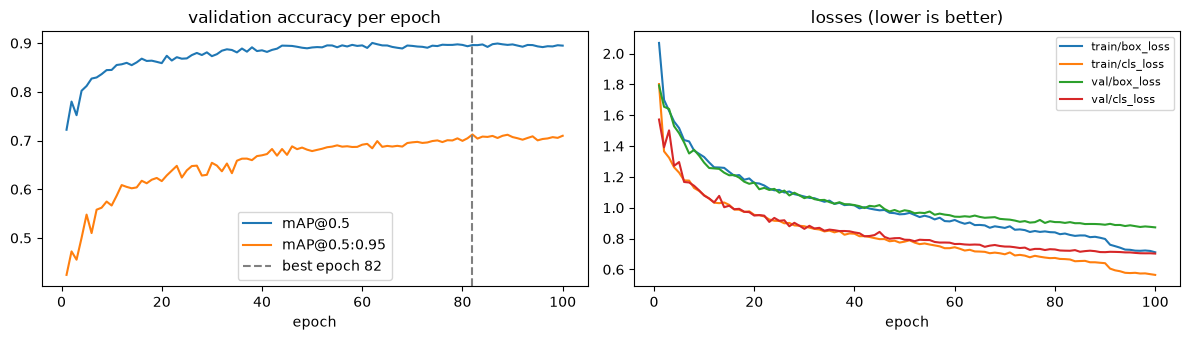

100 epochs; best epoch 82: validation mAP@0.5 0.896, mAP@0.5:0.95 0.712; image size 960


In [2]:
log = pd.read_csv(RUN / "results.csv")
log.columns = [c.strip() for c in log.columns]
best = log.loc[log["metrics/mAP50-95(B)"].idxmax()]
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].plot(log["epoch"], log["metrics/mAP50(B)"], label="mAP@0.5")
ax[0].plot(log["epoch"], log["metrics/mAP50-95(B)"], label="mAP@0.5:0.95")
ax[0].axvline(best["epoch"], color="grey", ls="--", label=f"best epoch {int(best['epoch'])}")
ax[0].set_title("validation accuracy per epoch")
ax[0].legend()
for col in ["train/box_loss", "train/cls_loss", "val/box_loss", "val/cls_loss"]:
    ax[1].plot(log["epoch"], log[col], label=col)
ax[1].set_title("losses (lower is better)")
ax[1].legend(fontsize=8)
for a in ax:
    a.set_xlabel("epoch")
plt.tight_layout()
plt.show()
print(f"{len(log)} epochs; best epoch {int(best['epoch'])}: validation mAP@0.5 {best['metrics/mAP50(B)']:.3f}, "
      f"mAP@0.5:0.95 {best['metrics/mAP50-95(B)']:.3f}; image size {colab['imgsz']}")  # fmt: skip

## 2. The data: objects per class and size (COCO sizes: small < 32×32 px, medium < 96×96, large)

In [3]:
rows = []
for split in ("train", "validation", "test"):
    for f in (DATA / "labels" / split).glob("*.txt"):
        for c, *box in read_labels(f, W, H):
            area = (box[2] - box[0]) * (box[3] - box[1])
            rows.append({"split": split, "class": NAMES[int(c)], "size": SIZES[int(np.digitize(area, (32**2, 96**2)))]})
objects = pd.DataFrame(rows)
display(objects.pivot_table(index="class", columns="split", aggfunc="size", fill_value=0)[["train", "validation", "test"]])
(objects[objects["split"] == "test"].groupby("class")["size"].value_counts(normalize=True).unstack()[list(SIZES)]
 .mul(100).round(0).rename(columns=lambda s: s + " %"))  # fmt: skip

split,train,validation,test
class,,,
blocked_path,359,58,60
obstacle,158,19,19
package,294,62,110
robot,3187,698,688
shelf,44875,10136,8431
worker,1156,290,262


size,small %,medium %,large %
class,,,
blocked_path,73.0,7.0,20.0
obstacle,16.0,37.0,47.0
package,28.0,68.0,4.0
robot,45.0,38.0,17.0
shelf,35.0,41.0,24.0
worker,63.0,30.0,7.0


## 3. Official test scores on this laptop, and speed vs accuracy

The same Ultralytics evaluation as on Colab, now on the CPU. Small differences to Colab are normal
(GPU and CPU round numbers differently). We also run it at image size 640 (the original size) to see
how much accuracy the faster setting costs.

In [4]:
official_cache = EXPORT / "vision_yolo_v1_official_test.json"  # about 20 minutes on a laptop CPU
if official_cache.exists():
    official = {int(k): v for k, v in json.loads(official_cache.read_text()).items()}
else:
    official = {}
    for imgsz in (960, 640):
        m = model.val(data=str(DATA_YAML), split="test", imgsz=imgsz, batch=8, device="cpu", workers=0,
                      plots=False, verbose=False, project=str(EXPORT / "val_runs"), name=f"test_{imgsz}", exist_ok=True)  # fmt: skip
        official[imgsz] = {"precision": m.box.mp, "recall": m.box.mr, "mAP50": m.box.map50, "mAP50_95": m.box.map,
                           "CPU ms per image (inference)": m.speed["inference"]}  # fmt: skip
    official_cache.write_text(json.dumps({k: {kk: float(vv) for kk, vv in v.items()} for k, v in official.items()}))
pd.DataFrame(official).T.round(3).rename_axis("image size")

,precision,recall,mAP50,mAP50_95,CPU ms per image (inference)
image size,,,,,
960,0.926,0.846,0.908,0.698,2315.564
640,0.935,0.797,0.876,0.652,747.385


In [5]:
print("Colab GPU, image size 960:", colab["test"], "| inference", colab["speed_ms_per_image"]["inference"], "ms per image")

Colab GPU, image size 960: {'precision': 0.926, 'recall': 0.846, 'mAP50': 0.908, 'mAP50_95': 0.699} | inference 17.84 ms per image


## 4. Where does it fail?

All validation and test images are run once (image size 960, every box with confidence >= 0.05 kept),
then every predicted box is matched to the true boxes (IoU >= 0.5, same class). From these matches we
compute precision / recall for any confidence threshold, by class, size and camera.

In [6]:
def predict_split(split):
    files = sorted((DATA / "images" / split).glob("*.jpg"))
    out = {}
    for f in files:  # one image at a time: a list of paths would be processed as one huge batch
        b = model.predict(str(f), imgsz=960, conf=0.05, device="cpu", verbose=False)[0].boxes
        out[f.stem] = np.column_stack([b.xyxy.numpy(), b.conf.numpy(), b.cls.numpy()]).astype(np.float32)
    return out


cache = EXPORT / "vision_yolo_v1_predictions.npz"
if cache.exists():
    stored = np.load(cache)
    preds = {s: {k.split("/", 1)[1]: stored[k] for k in stored.files if k.startswith(s + "/")} for s in ("validation", "test")}
else:
    start = time.time()
    preds = {s: predict_split(s) for s in ("validation", "test")}
    np.savez_compressed(cache, **{f"{s}/{k}": v for s, d in preds.items() for k, v in d.items()})
    print(f"predicted {sum(len(d) for d in preds.values())} images in {time.time() - start:.0f} s")
matched = {s: match_split(preds[s], DATA / "labels" / s, W, H) for s in preds}
for s, (p, t) in matched.items():
    print(f"{s:10s} {len(p):6,} predicted boxes, {len(t):6,} true objects")

validation 21,087 predicted boxes, 11,263 true objects
test       17,430 predicted boxes,  9,570 true objects


In [7]:
p_test, t_test = matched["test"]
by_class = pd.DataFrame({NAMES[c]: prf(p_test[p_test["cls"] == c], t_test[t_test["cls"] == c], 0.25)
                         for c in range(len(NAMES))}).T  # fmt: skip
print("Test, default confidence threshold 0.25:")
by_class.round(3)

Test, default confidence threshold 0.25:


,precision,recall,F1,boxes,objects
robot,0.894,0.799,0.844,615.0,688.0
worker,0.880,0.924,0.901,275.0,262.0
shelf,0.722,0.736,0.729,8599.0,8431.0
package,0.945,0.945,0.945,110.0,110.0
obstacle,0.810,0.895,0.850,21.0,19.0
blocked_path,0.950,0.950,0.950,60.0,60.0


**Recall by object size** (share of true objects found at confidence 0.25; `n` = number of objects):

size,small,medium,large
cls_name,,,
blocked_path,1.0 (n=44),0.5 (n=4),0.92 (n=12)
obstacle,0.33 (n=3),1.0 (n=7),1.0 (n=9)
package,0.87 (n=31),0.97 (n=75),1.0 (n=4)
robot,0.65 (n=310),0.93 (n=260),0.92 (n=118)
shelf,0.58 (n=2949),0.77 (n=3456),0.9 (n=2026)
worker,0.9 (n=165),0.96 (n=79),0.94 (n=18)


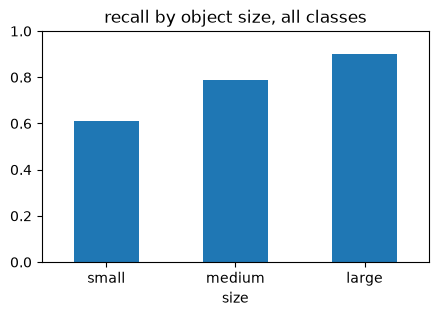

In [8]:
t = t_test.assign(found=t_test["conf_found"] >= 0.25, cls_name=t_test["cls"].map(dict(enumerate(NAMES))))
rec = t.pivot_table(index="cls_name", columns="size", values="found", aggfunc="mean")[list(SIZES)].round(2)
cnt = t.pivot_table(index="cls_name", columns="size", values="found", aggfunc="size")[list(SIZES)].fillna(0).astype(int)
display(rec.astype(str) + " (n=" + cnt.astype(str) + ")")
t.groupby("size")["found"].mean().reindex(SIZES).plot.bar(title="recall by object size, all classes", figsize=(5, 3), rot=0)
plt.ylim(0, 1)
plt.show()

**Recall by camera type** (cctv = high overview, aisle = along a picking aisle, hazard = aimed at a hazard, robot = on-board camera):

In [9]:
t["camera"] = t["frame"].map(frames["camera"])
safety = ["worker", "package", "obstacle", "blocked_path"]
cam = t.pivot_table(index="camera", columns="cls_name", values="found", aggfunc="mean").round(2)
cam["all classes"] = t.groupby("camera")["found"].mean().round(2)
cam["safety classes"] = t[t["cls_name"].isin(safety)].groupby("camera")["found"].mean().round(2)
cam

cls_name,blocked_path,obstacle,package,robot,shelf,worker,all classes,safety classes
camera,,,,,,,,
aisle,0.95,NaN,1.00,0.83,0.72,0.93,0.74,0.94
cctv,NaN,1.00,0.86,0.79,0.75,0.89,0.75,0.89
hazard,1.00,0.88,0.96,0.81,0.71,0.94,0.75,0.94
robot,1.00,NaN,0.00,0.75,0.73,1.00,0.74,0.94


## 5. Per-class confidence thresholds (chosen on validation)

One threshold for all classes is a compromise. For safety it is worse to **miss** a worker, a dropped
parcel, an obstacle or a closed aisle than to raise a false alarm, so:

* **safety classes** (worker, package, obstacle, blocked_path): the **lowest threshold whose precision
  is still >= 0.80** (the highest recall at that precision, with a margin for unseen cases);
* **robot, shelf**: the threshold with the best F1.

Thresholds are chosen on **validation**, then applied once to **test**.

In [10]:
p_val, t_val = matched["validation"]
thresholds = {}
for c, name in enumerate(NAMES):
    pv, tv = p_val[p_val["cls"] == c], t_val[t_val["cls"] == c]
    thresholds[name] = choose_threshold(pv, tv, min_precision=0.80 if name in safety else None)
compare = {}
for c, name in enumerate(NAMES):
    pt, tt = p_test[p_test["cls"] == c], t_test[t_test["cls"] == c]
    default, tuned = prf(pt, tt, 0.25), prf(pt, tt, thresholds[name])
    compare[name] = {"threshold": thresholds[name], "precision @0.25": default["precision"], "recall @0.25": default["recall"],
                     "precision tuned": tuned["precision"], "recall tuned": tuned["recall"],
                     "F1 @0.25": default["F1"], "F1 tuned": tuned["F1"]}  # fmt: skip
compare = pd.DataFrame(compare).T.round(3)
compare

,threshold,precision @0.25,recall @0.25,precision tuned,recall tuned,F1 @0.25,F1 tuned
robot,0.34,0.894,0.799,0.922,0.785,0.844,0.848
worker,0.13,0.880,0.924,0.817,0.935,0.901,0.872
shelf,0.36,0.722,0.736,0.812,0.687,0.729,0.744
package,0.05,0.945,0.945,0.891,0.964,0.945,0.926
obstacle,0.15,0.810,0.895,0.739,0.895,0.850,0.810
blocked_path,0.09,0.950,0.950,0.841,0.967,0.950,0.899


## 6. Examples (test images): green = true object, red = model (with tuned thresholds)

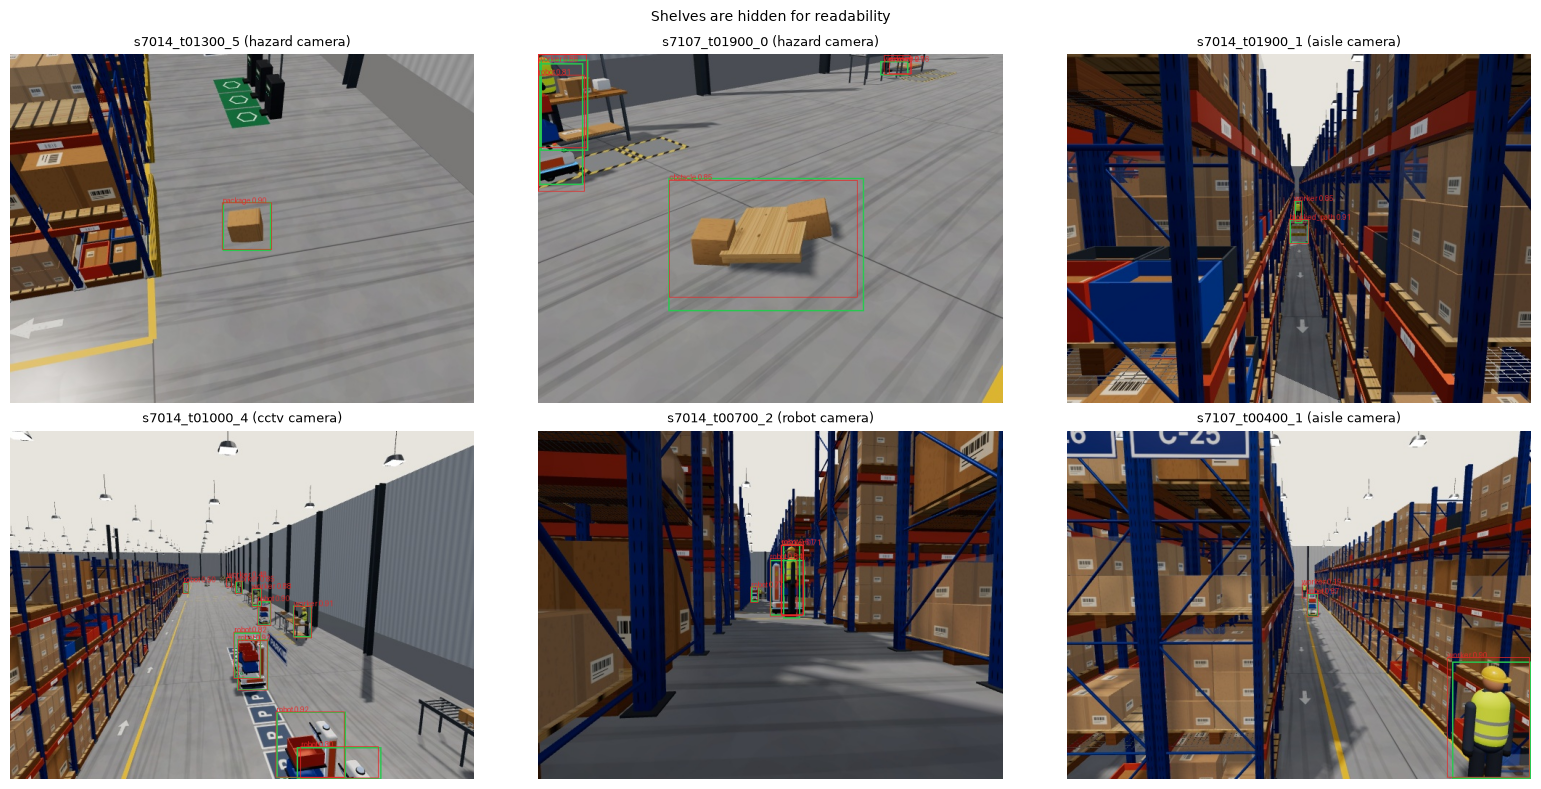

In [11]:
def show(frame, ax):
    img = Image.open(DATA / "images" / "test" / f"{frame}.jpg").convert("RGB")
    draw = ImageDraw.Draw(img)
    for c, *box in read_labels(DATA / "labels" / "test" / f"{frame}.txt", W, H):
        if NAMES[int(c)] != "shelf":
            draw.rectangle(box, outline=(40, 200, 80), width=2)
    for x1, y1, x2, y2, conf, c in preds["test"][frame]:
        name = NAMES[int(c)]
        if name != "shelf" and conf >= thresholds[name]:
            draw.rectangle([x1, y1, x2, y2], outline=(230, 40, 40), width=1)
            draw.text((x1, max(0, y1 - 10)), f"{name} {conf:.2f}", fill=(230, 40, 40))
    ax.imshow(img)
    ax.set_title(f"{frame} ({frames.loc[frame, 'camera']} camera)", fontsize=9)
    ax.axis("off")


test_frames = frames[frames["split"] == "test"]
picks = [test_frames[test_frames["camera"] == cam_type].index[i] for cam_type, i in
         [("hazard", 3), ("hazard", 40), ("aisle", 10), ("cctv", 5), ("robot", 2), ("aisle", 60)]]  # fmt: skip
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for frame, ax in zip(picks, axes.ravel(), strict=False):
    show(frame, ax)
plt.suptitle("Shelves are hidden for readability", fontsize=10)
plt.tight_layout()
plt.show()

**The hardest images:** the test images where the most workers, packages, obstacles or barriers were missed.

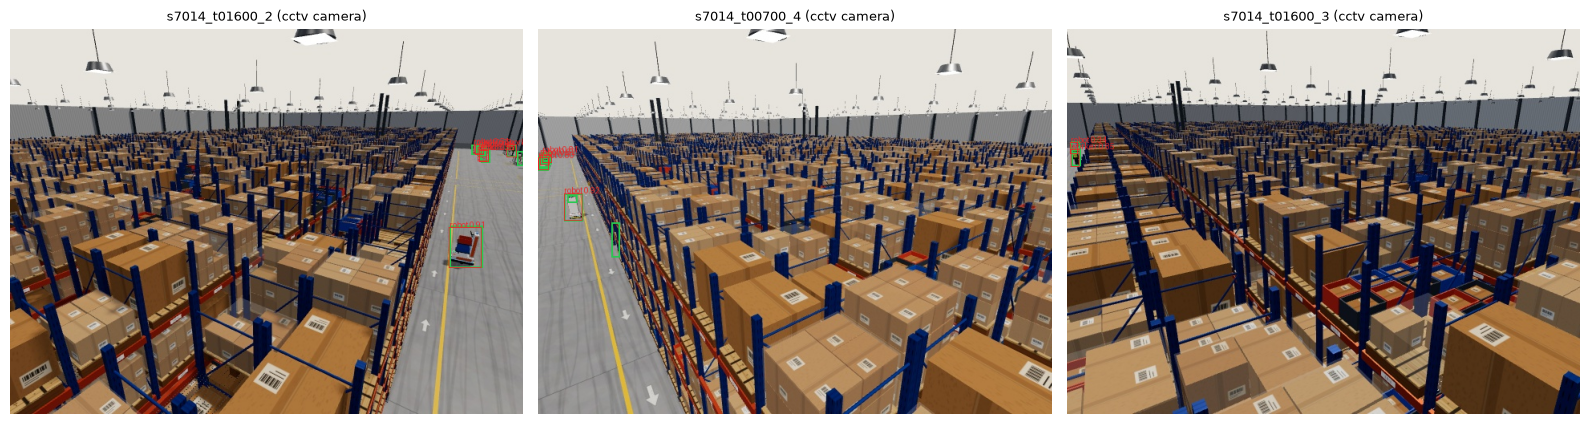

,missed,objects
cls,,
blocked_path,2,60
obstacle,2,19
package,4,110
worker,17,262


In [12]:
safety_ids = [NAMES.index(n) for n in safety]
missed = t_test[t_test["cls"].isin(safety_ids)].assign(miss=lambda d: d["conf_found"].isna()
          | (d["conf_found"] < d["cls"].map({i: thresholds[NAMES[i]] for i in safety_ids})))  # fmt: skip
worst = missed.groupby("frame")["miss"].sum().sort_values(ascending=False).head(3).index
fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
for frame, ax in zip(worst, axes, strict=False):
    show(frame, ax)
plt.tight_layout()
plt.show()
missed.groupby(missed["cls"].map(dict(enumerate(NAMES))))["miss"].agg(["sum", "size"]).rename(columns={"sum": "missed", "size": "objects"})

## 7. Save the evaluation (the app reads the tuned thresholds from here)

In [13]:
evaluation = {
    "model": "vision_yolo_v1",
    "evaluated_on": "laptop CPU",
    "test_official": {str(k): {kk: round(float(vv), 4) for kk, vv in v.items()} for k, v in official.items()},
    "test_colab_gpu": colab["test"],
    "test_by_class_conf_0.25": by_class.round(4).to_dict("index"),
    "test_recall_by_size": rec.to_dict("index"),
    "test_recall_by_camera": cam.to_dict("index"),
    "thresholds": thresholds,
    "threshold_rule": "safety classes: lowest threshold with precision >= 0.80 on validation; others: best F1 on validation",
    "test_with_thresholds": compare.to_dict("index"),
}
(RUN / "evaluation.json").write_text(json.dumps(evaluation, indent=2, default=float))
print("Saved models/vision_yolo_v1/evaluation.json")

Saved models/vision_yolo_v1/evaluation.json


## 8. Conclusions

**Test images (336, never used for training or for any choice here):**

| Setting | Precision | Recall | mAP@0.5 | mAP@0.5:0.95 | Time per image |
|---|---|---|---|---|---|
| Image size 960, Colab T4 GPU | 0.926 | 0.846 | 0.908 | 0.699 | 18 ms |
| Image size 960, laptop CPU | 0.926 | 0.846 | 0.908 | 0.699 | ~2.3 s |
| Image size 640, laptop CPU | 0.935 | 0.797 | 0.877 | 0.652 | ~0.75 s |

1. **The local evaluation reproduces Colab exactly** (same weights, same images).
2. **Safety classes are detected well:** with the default threshold 0.25, recall is 0.92 for
   workers, 0.95 for dropped parcels, 0.90 for obstacles and 0.95 for closed-aisle barriers, on
   every camera type (safety recall 0.89-0.94 per camera).
3. **Small objects are the weak spot:** recall for small robots (< 32 x 32 pixels) is 0.65 vs 0.93 for
   medium ones; small shelves 0.58. The hardest images are the wide CCTV overviews, where distant
   workers are only a few pixels tall.
4. **Per-class thresholds** (chosen on validation; safety classes: lowest threshold with precision
   >= 0.80) raise safety recall on test: workers 0.924 -> 0.935, parcels 0.945 -> 0.964, barriers
   0.950 -> 0.967 (obstacles unchanged 0.895), at the cost of more false alarms (precision 0.82-0.89
   instead of 0.88-0.95). This is the intended trade-off: a missed worker is worse than a false alarm.
   Note the small test counts (19 obstacles, 60 barriers): one object changes recall by 2-5 points.
5. **Speed on the laptop:** image size 640 is 3x faster (0.75 s) for 3 points less mAP@0.5. For the
   live Camera view in the app (one frame every few seconds) size 640 is used; 960 for offline checks.

**Next improvements** (vision v2): render more and larger images (1280 x 960) with more rare hazards,
label distant shelves consistently, and train a larger model (YOLO11m), then compare v1 and v2 on
the same, larger test set. **Limit:** scores are measured on simulator images; real cameras would
need domain randomisation and some labelled real footage.